###Task 1: Text Loading, Cleaning, Tokenisation & Padding

1.1
Load and inspect

In [3]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

# Using the 'python' engine and handling potential malformed quoting issues
df = pd.read_csv('IMDB Dataset.csv', engine='python', on_bad_lines='skip')

print("Shape:", df.shape)
print(df.head())
print("\nSentiment counts:")
print(df['sentiment'].value_counts())
print("\nMissing values:")
print(df.isnull().sum())

Shape: (28506, 2)
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive

Sentiment counts:
sentiment
positive    14266
negative    14240
Name: count, dtype: int64

Missing values:
review       0
sentiment    0
dtype: int64


1.2
Remove duplicates

In [4]:
rows_before = len(df)
duplicate_count = df.duplicated().sum()
print("Rows before:", rows_before)
print("Duplicate rows:", duplicate_count)

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print("Rows after:", len(df))

Rows before: 28506
Duplicate rows: 131
Rows after: 28375


1.3
Clean the text

In [5]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r"[^a-zA-Z']", ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

print("Before cleaning:")
print(df['review'].iloc[0])
df['review'] = df['review'].apply(clean_text)

print("\nAfter cleaning:")
print(df['review'].iloc[0])

Before cleaning:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show 

1.4
Review length analysis

Mean length: 229.79
Median length: 172.0
90th percentile: 450.0
95th percentile: 590.0


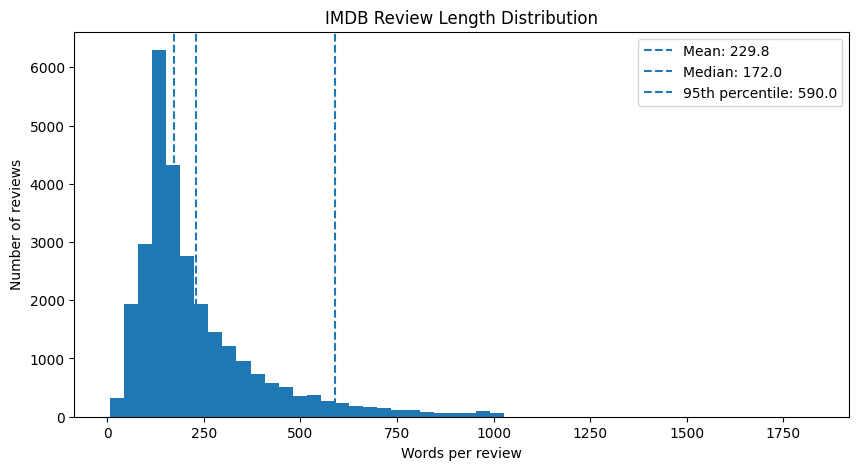

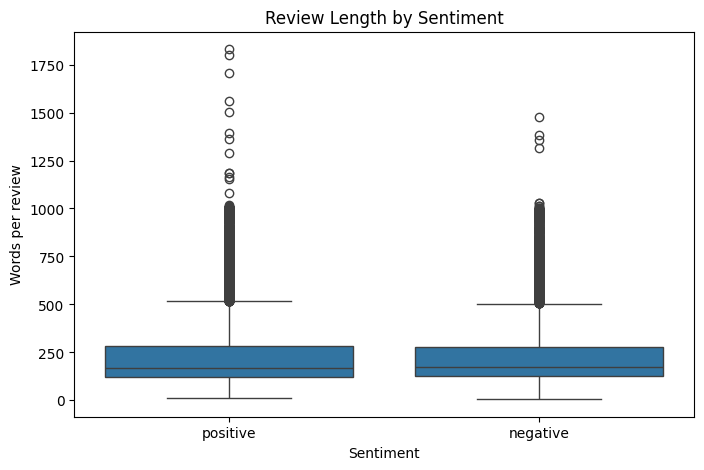

In [6]:
df['word_count'] = df['review'].apply(lambda x: len(x.split()))

mean_len = df['word_count'].mean()
median_len = df['word_count'].median()
p95_len = df['word_count'].quantile(0.95)
p90_len = df['word_count'].quantile(0.90)

print("Mean length:", round(mean_len, 2))
print("Median length:", round(median_len, 2))
print("90th percentile:", round(p90_len, 2))
print("95th percentile:", round(p95_len, 2))

plt.figure(figsize=(10, 5))
plt.hist(df['word_count'], bins=50)
plt.axvline(mean_len, linestyle='--', label=f'Mean: {mean_len:.1f}')
plt.axvline(median_len, linestyle='--', label=f'Median: {median_len:.1f}')
plt.axvline(p95_len, linestyle='--', label=f'95th percentile: {p95_len:.1f}')
plt.title('IMDB Review Length Distribution')
plt.xlabel('Words per review')
plt.ylabel('Number of reviews')
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='sentiment', y='word_count')
plt.title('Review Length by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Words per review')
plt.show()

1.5
Tokenise

In [7]:
df['sentiment'] = df['sentiment'].map({'positive': 1, 'negative': 0})
texts = df['review'].astype(str).to_numpy()
y = df['sentiment'].to_numpy()

X_train_text, X_test_text, y_train, y_test = train_test_split(
    texts, y, test_size=0.2, random_state=42, stratify=y
)

MAXLEN = max(10, int(round(p95_len / 10) * 10))
print("MAXLEN:", MAXLEN)

tokenizer = Tokenizer(num_words=10000, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_text)

sequences_train = tokenizer.texts_to_sequences(X_train_text)
sequences_test = tokenizer.texts_to_sequences(X_test_text)

word_items = sorted(tokenizer.word_index.items(), key=lambda item: item[1])
print("First 10 words in tokenizer index:")
print(word_items[:10])

print("\nExample integer sequence:")
print(sequences_train[0])

MAXLEN: 590
First 10 words in tokenizer index:
[('<OOV>', 1), ('the', 2), ('and', 3), ('a', 4), ('of', 5), ('to', 6), ('is', 7), ('in', 8), ('it', 9), ('i', 10)]

Example integer sequence:
[14, 77, 807, 25, 292, 158, 5, 2, 3211, 617, 5, 1191, 9350, 11, 55, 17, 4, 79, 1, 5, 2, 5977, 1420, 8, 728, 4, 227, 5, 2, 352, 6420, 61, 35, 278, 46, 3, 4, 8232, 358, 111, 2673, 4360, 36, 2, 1, 7017, 680, 6797, 908, 2744, 90, 1, 497, 1, 2220, 6, 1, 1708, 82, 2090, 281, 1, 241, 36, 95, 583, 2, 61, 100, 4, 707, 5, 82, 646, 190, 8, 4, 764, 1407, 3, 827, 248, 77, 73, 74, 4, 1, 152, 308, 2, 862, 5, 4, 1, 1623, 1, 5071, 670, 6, 26, 8401, 8, 621, 1, 4, 1, 764, 1407, 20, 4, 1, 262, 44, 2, 1, 2, 1407, 73, 214, 8, 2, 594, 707, 21, 4, 49, 55, 6, 25, 618, 269, 4020, 120, 334, 20, 2, 1, 1623, 6, 80, 47, 1, 93, 2, 7018, 1407, 153, 1, 36, 92, 262, 3, 7, 1, 4, 80, 21, 478, 98, 2145, 2346, 11, 1407, 1699, 100, 4, 170, 5, 5271, 30, 248, 77, 2, 862, 5, 2, 1, 1623, 8572, 137, 286, 3, 74, 2, 1623, 41, 5, 2, 94, 39, 8, 2,

1.6
Pad / truncate and split

In [8]:
X_train = pad_sequences(
    sequences_train, maxlen=MAXLEN, padding='pre', truncating='pre'
)
X_test = pad_sequences(
    sequences_test, maxlen=MAXLEN, padding='pre', truncating='pre'
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (22700, 590)
y_train shape: (22700,)
X_test shape: (5675, 590)
y_test shape: (5675,)


###Task 2: RNN Intuition, RNN vs ANN & Forward Propagation

2.1
Baseline ANN on text

In [9]:
from tensorflow import keras
from tensorflow.keras import layers

MAXLEN = X_train.shape[1]
VOCAB_SIZE = 10000

ann = keras.Sequential([
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=32, input_length=MAXLEN),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
ann.summary()
history_ann = ann.fit(X_train, y_train,epochs=5,batch_size=84,validation_split=0.1,verbose=1)

ann_loss, ann_accuracy = ann.evaluate(X_test, y_test, verbose=0)
print("ANN test loss:", ann_loss)
print("ANN test accuracy:", ann_accuracy)
print("ANN total parameters:", ann.count_params())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
244/244 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.7258 - loss: 0.4952 - val_accuracy: 0.8604 - val_loss: 0.3408
Epoch 2/5
244/244 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9342 - loss: 0.1793 - val_accuracy: 0.8678 - val_loss: 0.3352
Epoch 3/5
244/244 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9907 - loss: 0.0436 - val_accuracy: 0.8630 - val_loss: 0.4054
Epoch 4/5
244/244 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9987 - loss: 0.0096 - val_accuracy: 0.8604 - val_loss: 0.4854
Epoch 5/5
244/244 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9999 - loss: 0.0025 - val_accuracy: 0.8656 - val_loss: 0.4971
ANN test loss: 0.4975157082080841
ANN test accuracy: 0.8609691858291626
ANN total parameters: 1528449


2.3
Manual forward propagation in NumPy

h(1) = [0.30137427 0.37770932 0.30841154]
h(2) = [0.49118629 0.59019329 0.47349568]
h(3) = [0.6247438  0.65173231 0.55383266]
h(4) = [0.76872741 0.78201665 0.62840364]


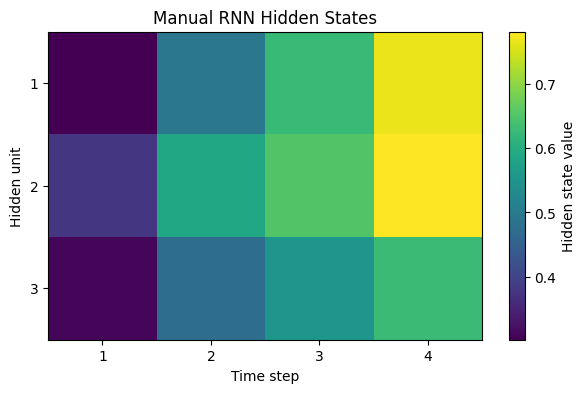

In [10]:
np.random.seed(42)

hidden_size = 3
input_size = 2

Wxh = np.random.rand(hidden_size, input_size) * 0.5
Whh = np.random.rand(hidden_size, hidden_size) * 0.5
b = np.random.rand(hidden_size) * 0.5

x_seq = np.random.rand(4, 2)
h = np.zeros(hidden_size)
hidden_states = []

for t in range(len(x_seq)):
    h = np.tanh(Wxh @ x_seq[t] + Whh @ h + b)
    hidden_states.append(h.copy())
    print(f"h({t + 1}) =", h)

hidden_states = np.array(hidden_states)

plt.figure(figsize=(7, 4))
plt.imshow(hidden_states.T, aspect='auto', cmap='viridis')
plt.colorbar(label='Hidden state value')
plt.xlabel('Time step')
plt.ylabel('Hidden unit')
plt.xticks(range(4), [1, 2, 3, 4])
plt.yticks(range(hidden_size), [1, 2, 3])
plt.title('Manual RNN Hidden States')
plt.show()

2.4
Verify against Keras

In [11]:
rnn = keras.Sequential([
    layers.SimpleRNN(3,return_sequences=True,use_bias=True,input_shape=(4, 2),activation='tanh')
])

rnn.build((None, 4, 2))
rnn.layers[0].set_weights([Wxh.T, Whh.T, b])

keras_output = rnn.predict(x_seq[np.newaxis, :, :], verbose=0)[0]

print("Manual hidden states:")
print(hidden_states)
print("\nKeras hidden states:")
print(keras_output)
print("\nMaximum absolute difference:")
print(np.max(np.abs(hidden_states - keras_output)))

np.testing.assert_allclose(hidden_states, keras_output, atol=1e-6)
print("Manual and Keras hidden states match.")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Manual hidden states:
[[0.30137427 0.37770932 0.30841154]
 [0.49118629 0.59019329 0.47349568]
 [0.6247438  0.65173231 0.55383266]
 [0.76872741 0.78201665 0.62840364]]

Keras hidden states:
[[0.30137426 0.3777093  0.3084115 ]
 [0.4911862  0.5901933  0.4734957 ]
 [0.6247438  0.65173227 0.5538326 ]
 [0.7687275  0.7820167  0.62840366]]

Maximum absolute difference:
8.915986748903038e-08
Manual and Keras hidden states match.


2.5
Parameter count by formula

In [12]:
units = 64
embedding_dim = 32
rnn_params = units * (embedding_dim + units + 1)

print("Formula parameter count:", rnn_params)

parameter_model = keras.Sequential([
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=embedding_dim),
    layers.SimpleRNN(units)
])

parameter_model.build((None, MAXLEN))
parameter_model.summary()
print("Keras SimpleRNN parameter count:", parameter_model.layers[1].count_params())

Formula parameter count: 6208


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         6,208 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,208 (1.24 MB)

 Trainable params: 326,208 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

Keras SimpleRNN parameter count: 6208


###Task 3: Types of RNN & Sentiment Analysis with SimpleRNN

3.1
Types of RNN — shape demonstration

In [13]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

dummy = tf.random.normal((4, 10, 8))

one_to_one = keras.Sequential([
    layers.Input(shape=(8,)),
    layers.Dense(1)
])
one_to_one_output = one_to_one(tf.random.normal((4, 8)))

one_to_many = keras.Sequential([
    layers.Input(shape=(8,)),
    layers.RepeatVector(10),
    layers.SimpleRNN(16, return_sequences=True)
])
one_to_many_output = one_to_many(tf.random.normal((4, 8)))

many_to_one = keras.Sequential([
    layers.Input(shape=(10, 8)),
    layers.SimpleRNN(16, return_sequences=False)
])
many_to_one_output = many_to_one(dummy)

many_to_many = keras.Sequential([
    layers.Input(shape=(10, 8)),
    layers.SimpleRNN(16, return_sequences=True)
])
many_to_many_output = many_to_many(dummy)

print("One-to-one output shape:", one_to_one_output.shape)
print("One-to-many output shape:", one_to_many_output.shape)
print("Many-to-one output shape:", many_to_one_output.shape)
print("Many-to-many output shape:", many_to_many_output.shape)

shape_table = pd.DataFrame({
    "Type": ["One-to-one", "One-to-many", "Many-to-one", "Many-to-many"],
    "Input shape": ["(4, 8)", "(4, 8)", "(4, 10, 8)", "(4, 10, 8)"],
    "Output shape": [
        str(tuple(one_to_one_output.shape)),
        str(tuple(one_to_many_output.shape)),
        str(tuple(many_to_one_output.shape)),
        str(tuple(many_to_many_output.shape))
    ],
    "return_sequences": ["Not applicable", "True", "False", "True"],
    "Example": [
        "Image classification",
        "Image captioning",
        "Sentiment analysis",
        "Named-entity tagging / translation"
    ]
})
display(shape_table)

One-to-one output shape: (4, 1)
One-to-many output shape: (4, 10, 16)
Many-to-one output shape: (4, 16)
Many-to-many output shape: (4, 10, 16)


,Type,Input shape,Output shape,return_sequences,Example
0,One-to-one,"(4, 8)","(4, 1)",Not applicable,Image classification
1,One-to-many,"(4, 8)","(4, 10, 16)",True,Image captioning
2,Many-to-one,"(4, 10, 8)","(4, 16)",False,Sentiment analysis
3,Many-to-many,"(4, 10, 8)","(4, 10, 16)",True,Named-entity tagging / translation


3.3
Build the SimpleRNN sentiment model

In [14]:
MAXLEN = X_train.shape[1]
VOCAB_SIZE = 10000

def build_model(model_type='rnn', units=64):
    model = keras.Sequential([
        layers.Input(shape=(MAXLEN,)),
        layers.Embedding(input_dim=VOCAB_SIZE, output_dim=32),
        layers.SimpleRNN(units),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

model_rnn = build_model('rnn', units=64)
model_rnn.summary()

rnn_parameter_count = 64 * (32 + 64 + 1)
print("SimpleRNN parameters by formula:", rnn_parameter_count)
print("SimpleRNN parameters from model:", model_rnn.layers[2].count_params())

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_5 (SimpleRNN)        │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

SimpleRNN parameters by formula: 6208
SimpleRNN parameters from model: 65


3.4
Train and plot

Epoch 1/15
227/227 ━━━━━━━━━━━━━━━━━━━━ 14s 51ms/step - accuracy: 0.6745 - loss: 0.5932 - val_accuracy: 0.7313 - val_loss: 0.5585
Epoch 2/15
227/227 ━━━━━━━━━━━━━━━━━━━━ 10s 45ms/step - accuracy: 0.7353 - loss: 0.5578 - val_accuracy: 0.7366 - val_loss: 0.6010
Epoch 3/15
227/227 ━━━━━━━━━━━━━━━━━━━━ 10s 45ms/step - accuracy: 0.8546 - loss: 0.3472 - val_accuracy: 0.8278 - val_loss: 0.4231
Epoch 4/15
227/227 ━━━━━━━━━━━━━━━━━━━━ 10s 45ms/step - accuracy: 0.8969 - loss: 0.2610 - val_accuracy: 0.8278 - val_loss: 0.4254
Epoch 5/15
227/227 ━━━━━━━━━━━━━━━━━━━━ 10s 45ms/step - accuracy: 0.9384 - loss: 0.1720 - val_accuracy: 0.7722 - val_loss: 0.5137
Epoch 6/15
227/227 ━━━━━━━━━━━━━━━━━━━━ 10s 45ms/step - accuracy: 0.9657 - loss: 0.1047 - val_accuracy: 0.8216 - val_loss: 0.5700
Training time (seconds): 65.66
Epochs completed: 6


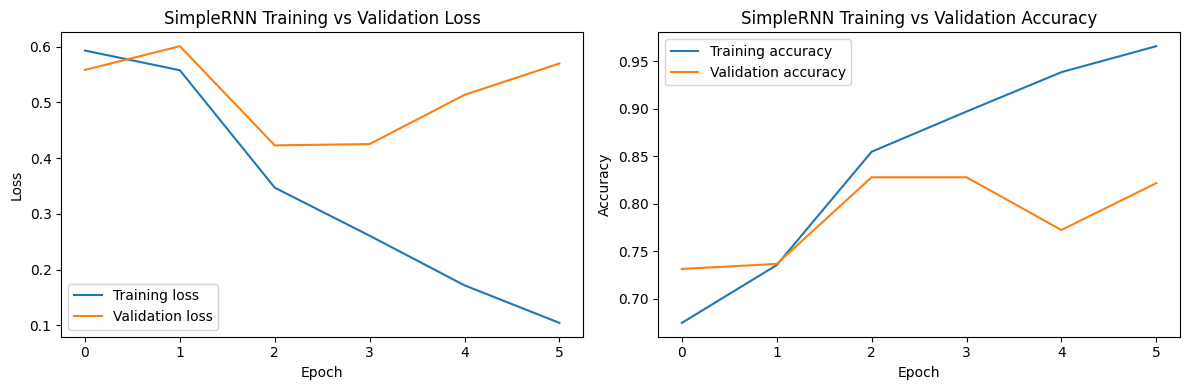

In [15]:
import time
import matplotlib.pyplot as plt

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

start_time = time.time()

history_rnn = model_rnn.fit(
    X_train, y_train,
    epochs=15,
    batch_size=90,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

training_time = time.time() - start_time
print("Training time (seconds):", round(training_time, 2))
print("Epochs completed:", len(history_rnn.history['loss']))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history_rnn.history['loss'], label='Training loss')
ax[0].plot(history_rnn.history['val_loss'], label='Validation loss')
ax[0].set_title('SimpleRNN Training vs Validation Loss')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].legend()

ax[1].plot(history_rnn.history['accuracy'], label='Training accuracy')
ax[1].plot(history_rnn.history['val_accuracy'], label='Validation accuracy')
ax[1].set_title('SimpleRNN Training vs Validation Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].legend()

plt.tight_layout()
plt.show()

3.5
Evaluate

Test accuracy: 0.8343612334801762

Classification report:
              precision    recall  f1-score   support

    negative       0.84      0.82      0.83      2828
    positive       0.83      0.85      0.84      2847

    accuracy                           0.83      5675
   macro avg       0.83      0.83      0.83      5675
weighted avg       0.83      0.83      0.83      5675

ROC-AUC: 0.9019342303792325


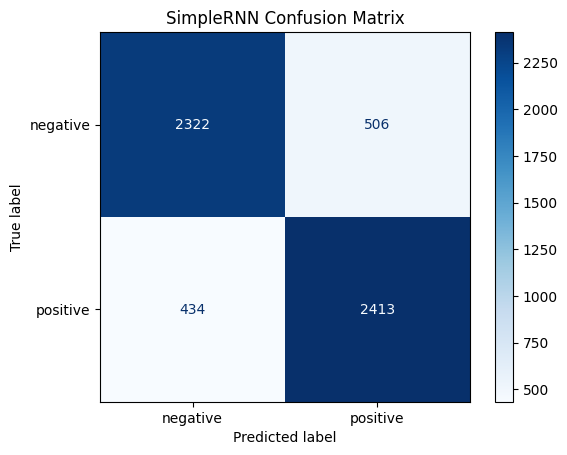

{'accuracy': 0.8343612334801762, 'roc_auc': np.float64(0.9019342303792325), 'classification_report': {'negative': {'precision': 0.8425253991291727, 'recall': 0.8210749646393211, 'f1-score': 0.8316618911174785, 'support': 2828.0}, 'positive': {'precision': 0.8266529633436108, 'recall': 0.8475588338602037, 'f1-score': 0.836975372875477, 'support': 2847.0}, 'accuracy': 0.8343612334801762, 'macro avg': {'precision': 0.8345891812363917, 'recall': 0.8343168992497624, 'f1-score': 0.8343186319964777, 'support': 5675.0}, 'weighted avg': {'precision': 0.8345626106390416, 'recall': 0.8343612334801762, 'f1-score': 0.8343275268117555, 'support': 5675.0}}, 'confusion_matrix': [[2322, 506], [434, 2413]]}


In [16]:
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, ConfusionMatrixDisplay
)

y_pred_prob_rnn = model_rnn.predict(X_test, verbose=0).ravel()
y_pred_rnn = (y_pred_prob_rnn >= 0.5).astype(int)

test_accuracy_rnn = accuracy_score(y_test, y_pred_rnn)
test_auc_rnn = roc_auc_score(y_test, y_pred_prob_rnn)

print("Test accuracy:", test_accuracy_rnn)
print("\nClassification report:")
print(classification_report(y_test, y_pred_rnn, target_names=['negative', 'positive']))
print("ROC-AUC:", test_auc_rnn)

cm = confusion_matrix(y_test, y_pred_rnn)
ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['negative', 'positive']).plot(cmap='Blues')
plt.title('SimpleRNN Confusion Matrix')
plt.show()

results = {}
results['SimpleRNN'] = {
    'accuracy': test_accuracy_rnn,
    'roc_auc': test_auc_rnn,
    'classification_report': classification_report(
        y_test, y_pred_rnn, target_names=['negative', 'positive'], output_dict=True
    ),
    'confusion_matrix': cm.tolist()
}

print(results['SimpleRNN'])

###Task 4: Backpropagation Through Time & Problems with RNN

4.1
BPTT — Markdown

Backpropagation Through Time (BPTT) trains an RNN by unrolling it across its time steps, creating a deep computation graph with the same weights reused at each step. The loss at the final step sends gradients backward through every time step. The gradient for an early hidden state is a product of Jacobian terms involving the recurrent weight matrix and the derivative of the activation function.

For a tanh RNN, the gradient contains repeated factors involving Whh and 1 - h(t)^2. The gradient with respect to a shared weight is the sum of its contributions from every time step. This repeated multiplication explains why gradients can become very small or very large as the sequence gets longer.

4.2
Vanishing and exploding gradients — Markdown

When repeated gradient factors have magnitude below 1, their product can shrink exponentially. This is the vanishing gradient problem: early words have little influence on learning. When factors are effectively larger than 1, gradients can grow exponentially, causing unstable updates, loss spikes, or NaN values. A SimpleRNN often struggles to learn long-range dependencies and may have a short effective memory, roughly 10–20 time steps in many practical settings.

4.2
Measure gradient flow with GradientTape

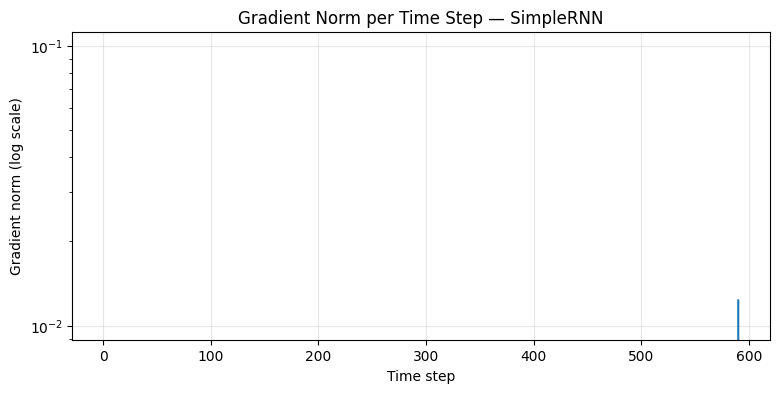

In [23]:
MAXLEN = X_train.shape[1]
VOCAB_SIZE = 10000

gradient_model = keras.Sequential([
    layers.Input(shape=(MAXLEN,)),
    layers.Embedding(VOCAB_SIZE, 32),
    layers.SimpleRNN(64, return_sequences=True),
    layers.Lambda(lambda x: x[:, -1, :]),
    layers.Dense(1, activation='sigmoid')
])

gradient_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

x_batch = tf.convert_to_tensor(X_train[:64], dtype=tf.int32)
y_batch = tf.convert_to_tensor(y_train[:64], dtype=tf.float32)

with tf.GradientTape() as tape:
    embedded = gradient_model.layers[0](x_batch)
    hidden_states = gradient_model.layers[1](embedded)
    tape.watch(hidden_states)
    final_state = hidden_states[:, -1, :]
    predictions = gradient_model.layers[-1](final_state)
    loss = tf.reduce_mean(keras.losses.binary_crossentropy(y_batch, tf.squeeze(predictions, axis=-1)))

grads = tape.gradient(loss, hidden_states)
gradient_norms = tf.reduce_mean(tf.norm(grads, axis=-1), axis=0).numpy()
plt.figure(figsize=(9, 4))
plt.plot(range(1, MAXLEN + 1), gradient_norms)
plt.yscale('log')
plt.xlabel('Time step')
plt.ylabel('Gradient norm (log scale)')
plt.title('Gradient Norm per Time Step — SimpleRNN')
plt.grid(True, alpha=0.3)
plt.show()

4.3
Accuracy vs sequence length

Sequence length: 50 Test accuracy: 0.7343
Sequence length: 100 Test accuracy: 0.6389
Sequence length: 200 Test accuracy: 0.8085
Sequence length: 300 Test accuracy: 0.8109


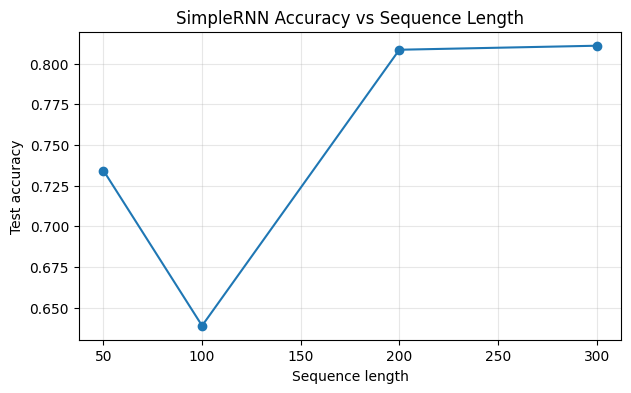

In [24]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import accuracy_score

sequence_lengths = [50, 100, 200, 300]
length_accuracies = []

train_sequences = tokenizer.texts_to_sequences(X_train_text)
test_sequences = tokenizer.texts_to_sequences(X_test_text)

for seq_len in sequence_lengths:
    tf.keras.utils.set_random_seed(42)
    x_train_len = pad_sequences(train_sequences, maxlen=seq_len, padding='pre', truncating='pre')
    x_test_len = pad_sequences(test_sequences, maxlen=seq_len, padding='pre', truncating='pre')

    length_model = keras.Sequential([
        layers.Input(shape=(seq_len,)),
        layers.Embedding(VOCAB_SIZE, 32),
        layers.SimpleRNN(64),
        layers.Dense(1, activation='sigmoid')
    ])
    length_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    length_model.fit(x_train_len, y_train, epochs=8, batch_size=64, validation_split=0.1, verbose=0)

    pred = (length_model.predict(x_test_len, verbose=0).ravel() >= 0.5).astype(int)
    acc = accuracy_score(y_test, pred)
    length_accuracies.append(acc)
    print("Sequence length:", seq_len, "Test accuracy:", round(acc, 4))

plt.figure(figsize=(7, 4))
plt.plot(sequence_lengths, length_accuracies, marker='o')
plt.xlabel('Sequence length')
plt.ylabel('Test accuracy')
plt.title('SimpleRNN Accuracy vs Sequence Length')
plt.grid(True, alpha=0.3)
plt.show()

4.4
Exploding gradient demo and clipping

Epoch 1/5
320/320 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - accuracy: 0.5343 - loss: 0.7150 - val_accuracy: 0.5586 - val_loss: 0.7252
Epoch 2/5
320/320 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - accuracy: 0.6203 - loss: 0.6493 - val_accuracy: 0.5471 - val_loss: 0.7168
Epoch 3/5
320/320 ━━━━━━━━━━━━━━━━━━━━ 14s 44ms/step - accuracy: 0.5821 - loss: nan - val_accuracy: 0.5000 - val_loss: nan
Epoch 4/5
320/320 ━━━━━━━━━━━━━━━━━━━━ 21s 47ms/step - accuracy: 0.4982 - loss: nan - val_accuracy: 0.5000 - val_loss: nan
Epoch 5/5
320/320 ━━━━━━━━━━━━━━━━━━━━ 14s 44ms/step - accuracy: 0.4982 - loss: nan - val_accuracy: 0.5000 - val_loss: nan
Epoch 1/5
320/320 ━━━━━━━━━━━━━━━━━━━━ 21s 51ms/step - accuracy: 0.5083 - loss: 0.7398 - val_accuracy: 0.5419 - val_loss: 0.7090
Epoch 2/5
320/320 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - accuracy: 0.5494 - loss: 0.7146 - val_accuracy: 0.5093 - val_loss: 0.7081
Epoch 3/5
320/320 ━━━━━━━━━━━━━━━━━━━━ 15s 48ms/step - accuracy: 0.5615 - loss: 0.7054 - val_accuracy: 0.5330 - val

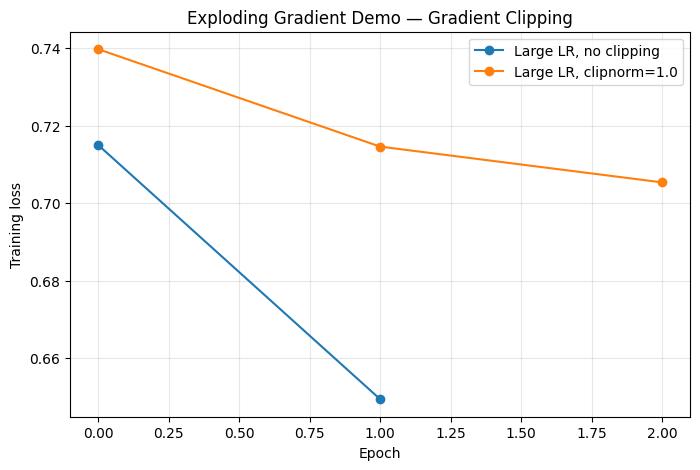

In [25]:
def build_clip_model(clip_norm=None):
    optimizer = keras.optimizers.Adam(learning_rate=0.05, clipnorm=clip_norm)
    model = keras.Sequential([
        layers.Input(shape=(MAXLEN,)),
        layers.Embedding(VOCAB_SIZE, 32),
        layers.SimpleRNN(64),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    return model

tf.keras.utils.set_random_seed(42)
model_large_lr = build_clip_model()
history_large_lr = model_large_lr.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1, verbose=1)

tf.keras.utils.set_random_seed(42)
model_clipped = build_clip_model(clip_norm=1.0)
history_clipped = model_clipped.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1, verbose=1)

plt.figure(figsize=(8, 5))
plt.plot(history_large_lr.history['loss'], marker='o', label='Large LR, no clipping')
plt.plot(history_clipped.history['loss'], marker='o', label='Large LR, clipnorm=1.0')
plt.xlabel('Epoch')
plt.ylabel('Training loss')
plt.title('Exploding Gradient Demo — Gradient Clipping')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

###Task 5: LSTM — Long Short-Term Memory

5.2
WHY LSTM fixes vanishing gradients — Markdown

The cell state is updated using addition and element-wise multiplication. Along the cell-state path, the gradient is multiplied by the forget-gate value f(t). When this gate stays close to 1, the gradient can pass across many time steps with less shrinkage than in a basic tanh RNN. This helps LSTM preserve useful information over longer sequences, although it does not guarantee that vanishing gradients will never occur.

5.3
Parameter count by formula

In [27]:
MAXLEN = X_train.shape[1]
VOCAB_SIZE = 10000

lstm_units = 64
embedding_dim = 32
lstm_params = 4 * lstm_units * (embedding_dim + lstm_units + 1)
print("LSTM parameters by formula:", lstm_params)

parameter_model_lstm = keras.Sequential([
    layers.Input(shape=(MAXLEN,)),
    layers.Embedding(VOCAB_SIZE, embedding_dim),
    layers.LSTM(lstm_units)
])
parameter_model_lstm.build((None, MAXLEN))
parameter_model_lstm.summary()
print("LSTM parameters from Keras:", parameter_model_lstm.layers[1].count_params())

LSTM parameters by formula: 24832


Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_15 (Embedding)        │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        24,832 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344,832 (1.32 MB)

 Trainable params: 344,832 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

LSTM parameters from Keras: 24832


5.5
Build, train and evaluate the LSTM

Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_16 (Embedding)        │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344,897 (1.32 MB)

 Trainable params: 344,897 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
227/227 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7272 - loss: 0.5247 - val_accuracy: 0.8489 - val_loss: 0.3628
Epoch 2/15
227/227 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.8851 - loss: 0.2972 - val_accuracy: 0.8670 - val_loss: 0.3574
Epoch 3/15
227/227 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.8861 - loss: 0.2799 - val_accuracy: 0.8700 - val_loss: 0.3702
Epoch 4/15
227/227 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.9234 - loss: 0.2092 - val_accuracy: 0.8181 - val_loss: 0.6056
Epoch 5/15
227/227 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.9349 - loss: 0.1851 - val_accuracy: 0.8564 - val_loss: 0.4690
LSTM training time (seconds): 31.69


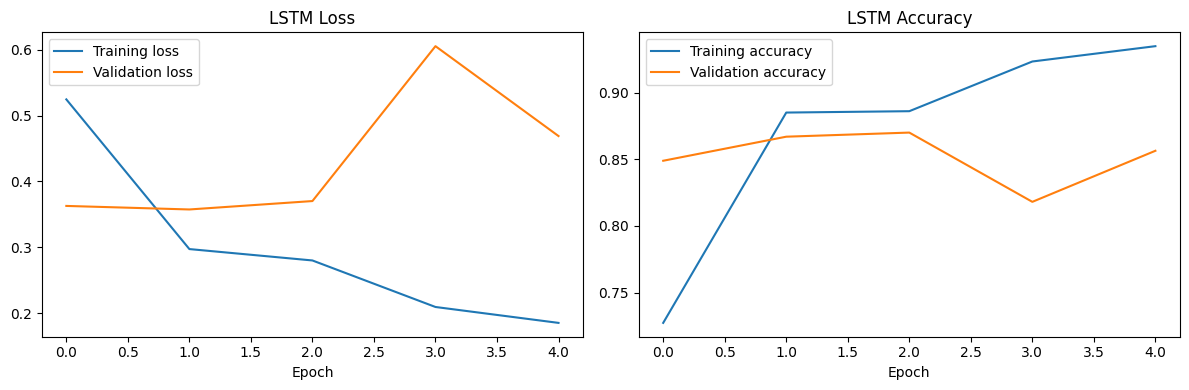

Test accuracy: 0.8697797356828194
              precision    recall  f1-score   support

    negative       0.83      0.92      0.88      2828
    positive       0.91      0.82      0.86      2847

    accuracy                           0.87      5675
   macro avg       0.87      0.87      0.87      5675
weighted avg       0.87      0.87      0.87      5675

ROC-AUC: 0.9408166938175075


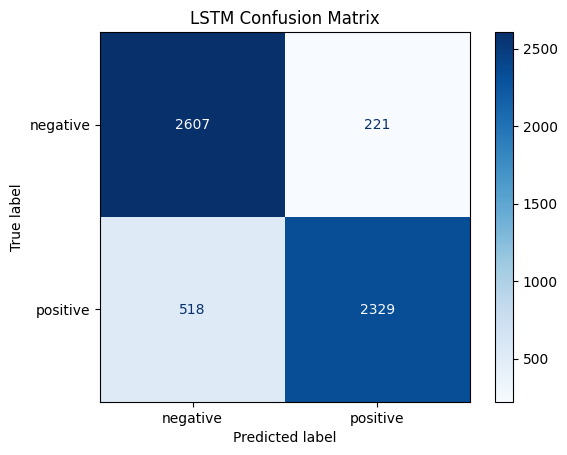

{'accuracy': 0.8697797356828194, 'roc_auc': np.float64(0.9408166938175075), 'classification_report': {'negative': {'precision': 0.83424, 'recall': 0.9218528995756718, 'f1-score': 0.8758609104653116, 'support': 2828.0}, 'positive': {'precision': 0.9133333333333333, 'recall': 0.8180540920266948, 'f1-score': 0.8630720770798592, 'support': 2847.0}, 'accuracy': 0.8697797356828194, 'macro avg': {'precision': 0.8737866666666667, 'recall': 0.8699534958011833, 'f1-score': 0.8694664937725853, 'support': 5675.0}, 'weighted avg': {'precision': 0.8739190696035242, 'recall': 0.8697797356828194, 'f1-score': 0.8694450851528212, 'support': 5675.0}}, 'confusion_matrix': [[2607, 221], [518, 2329]], 'training_time_seconds': 31.692243337631226}


In [28]:
import time
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,roc_auc_score, ConfusionMatrixDisplay)

def build_model(model_type='lstm', units=64):
    model = keras.Sequential([
        layers.Input(shape=(MAXLEN,)),
        layers.Embedding(input_dim=VOCAB_SIZE, output_dim=32),
        layers.LSTM(units),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),loss='binary_crossentropy',metrics=['accuracy'])
    return model

model_lstm = build_model('lstm', units=64)
model_lstm.summary()

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

start_time = time.time()
history_lstm = model_lstm.fit(X_train, y_train,epochs=15,batch_size=90,validation_split=0.1,callbacks=[early_stop],verbose=1)
lstm_training_time = time.time() - start_time
print("LSTM training time (seconds):", round(lstm_training_time, 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history_lstm.history['loss'], label='Training loss')
ax[0].plot(history_lstm.history['val_loss'], label='Validation loss')
ax[0].set_title('LSTM Loss')
ax[0].set_xlabel('Epoch')
ax[0].legend()

ax[1].plot(history_lstm.history['accuracy'], label='Training accuracy')
ax[1].plot(history_lstm.history['val_accuracy'], label='Validation accuracy')
ax[1].set_title('LSTM Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].legend()
plt.tight_layout()
plt.show()

y_prob_lstm = model_lstm.predict(X_test, verbose=0).ravel()
y_pred_lstm = (y_prob_lstm >= 0.5).astype(int)
acc_lstm = accuracy_score(y_test, y_pred_lstm)
auc_lstm = roc_auc_score(y_test, y_prob_lstm)

print("Test accuracy:", acc_lstm)
print(classification_report(y_test, y_pred_lstm, target_names=['negative', 'positive']))
print("ROC-AUC:", auc_lstm)

ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred_lstm),display_labels=['negative', 'positive']).plot(cmap='Blues')
plt.title('LSTM Confusion Matrix')
plt.show()

if 'results' not in globals():
    results = {}

results['LSTM'] = {
    'accuracy': acc_lstm,
    'roc_auc': auc_lstm,
    'classification_report': classification_report(
        y_test, y_pred_lstm, target_names=['negative', 'positive'], output_dict=True
    ),
    'confusion_matrix': confusion_matrix(y_test, y_pred_lstm).tolist(),
    'training_time_seconds': lstm_training_time
}
print(results['LSTM'])

5.6
Gradient flow comparison

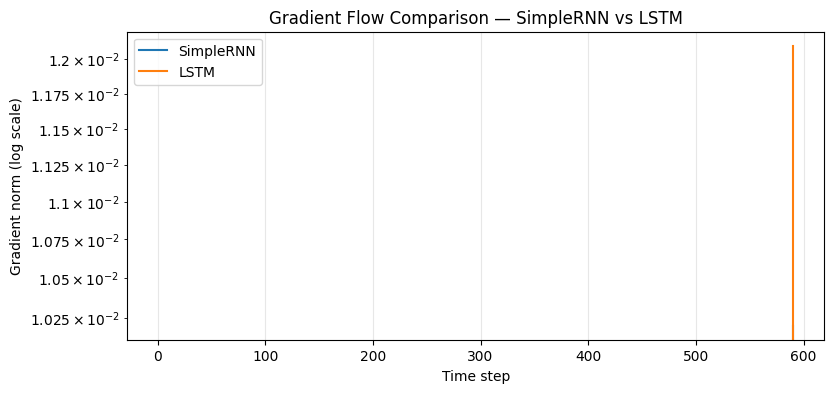

SimpleRNN earliest-step gradient: 0.0
LSTM earliest-step gradient: 0.0
LSTM / SimpleRNN earliest-step gradient ratio: 0.0


In [29]:
x_batch = tf.convert_to_tensor(X_train[:64], dtype=tf.int32)
y_batch = tf.convert_to_tensor(y_train[:64], dtype=tf.float32)

def hidden_state_gradients(cell_type):
    inputs = keras.Input(shape=(MAXLEN,))
    embedded = layers.Embedding(VOCAB_SIZE, 32)(inputs)

    if cell_type == 'lstm':
        hidden_seq = layers.LSTM(64, return_sequences=True)(embedded)
    else:
        hidden_seq = layers.SimpleRNN(64, return_sequences=True)(embedded)

    final_state = layers.Lambda(lambda x: x[:, -1, :])(hidden_seq)
    output = layers.Dense(1, activation='sigmoid')(final_state)
    model = keras.Model(inputs, [output, hidden_seq])

    with tf.GradientTape() as tape:
        pred, hidden = model(x_batch, training=False)
        tape.watch(hidden)
        loss = tf.reduce_mean(
            keras.losses.binary_crossentropy(y_batch, tf.squeeze(pred, axis=-1))
        )

    grad = tape.gradient(loss, hidden)
    return tf.reduce_mean(tf.norm(grad, axis=-1), axis=0).numpy()

simple_rnn_grad = hidden_state_gradients('rnn')
lstm_grad = hidden_state_gradients('lstm')

plt.figure(figsize=(9, 4))
plt.plot(range(1, MAXLEN + 1), simple_rnn_grad, label='SimpleRNN')
plt.plot(range(1, MAXLEN + 1), lstm_grad, label='LSTM')
plt.yscale('log')
plt.xlabel('Time step')
plt.ylabel('Gradient norm (log scale)')
plt.title('Gradient Flow Comparison — SimpleRNN vs LSTM')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

eps = 1e-12
print("SimpleRNN earliest-step gradient:", simple_rnn_grad[0])
print("LSTM earliest-step gradient:", lstm_grad[0])
print("LSTM / SimpleRNN earliest-step gradient ratio:",
      lstm_grad[0] / max(simple_rnn_grad[0], eps))

5.7
Stacked LSTM

Model: "sequential_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_19 (Embedding)        │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 590, 64)        │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 357,281 (1.36 MB)

 Trainable params: 357,281 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
320/320 ━━━━━━━━━━━━━━━━━━━━ 18s 46ms/step - accuracy: 0.7364 - loss: 0.5253 - val_accuracy: 0.8189 - val_loss: 0.4156
Epoch 2/15
320/320 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.8773 - loss: 0.3096 - val_accuracy: 0.8529 - val_loss: 0.3544
Epoch 3/15
320/320 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.9017 - loss: 0.2617 - val_accuracy: 0.8537 - val_loss: 0.3985
Epoch 4/15
320/320 ━━━━━━━━━━━━━━━━━━━━ 13s 41ms/step - accuracy: 0.9268 - loss: 0.2046 - val_accuracy: 0.8515 - val_loss: 0.3987
Epoch 5/15
320/320 ━━━━━━━━━━━━━━━━━━━━ 15s 46ms/step - accuracy: 0.9351 - loss: 0.1844 - val_accuracy: 0.8630 - val_loss: 0.3936
Stacked LSTM test accuracy: 0.8518061674008811
              precision    recall  f1-score   support

    negative       0.85      0.86      0.85      2828
    positive       0.86      0.84      0.85      2847

    accuracy                           0.85      5675
   macro avg       0.85      0.85      0.85      5675
weighted avg       0.85      0.

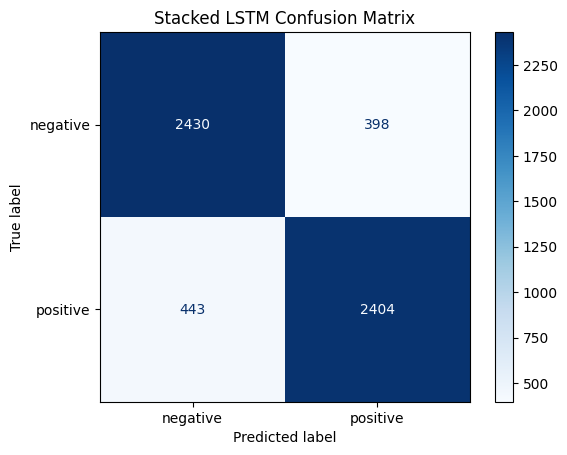

{'accuracy': 0.8518061674008811, 'roc_auc': np.float64(0.9255241006563399), 'classification_report': {'negative': {'precision': 0.8458057779324748, 'recall': 0.8592644978783592, 'f1-score': 0.8524820206981232, 'support': 2828.0}, 'positive': {'precision': 0.8579586009992862, 'recall': 0.8443976115208992, 'f1-score': 0.8511240927597805, 'support': 2847.0}, 'accuracy': 0.8518061674008811, 'macro avg': {'precision': 0.8518821894658806, 'recall': 0.8518310546996293, 'f1-score': 0.8518030567289518, 'support': 5675.0}, 'weighted avg': {'precision': 0.8519025333987676, 'recall': 0.8518061674008811, 'f1-score': 0.851800783545619, 'support': 5675.0}}, 'confusion_matrix': [[2430, 398], [443, 2404]], 'training_time_seconds': 70.41346311569214}


In [30]:
stacked_model = keras.Sequential([
    layers.Input(shape=(MAXLEN,)),
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=32),
    layers.LSTM(64, return_sequences=True),
    layers.LSTM(32),
    layers.Dense(1, activation='sigmoid')
])

stacked_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
stacked_model.summary()

start_time = time.time()
history_stacked = stacked_model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=3, restore_best_weights=True
    )],
    verbose=1
)
stacked_training_time = time.time() - start_time

y_prob_stacked = stacked_model.predict(X_test, verbose=0).ravel()
y_pred_stacked = (y_prob_stacked >= 0.5).astype(int)
acc_stacked = accuracy_score(y_test, y_pred_stacked)
auc_stacked = roc_auc_score(y_test, y_prob_stacked)

print("Stacked LSTM test accuracy:", acc_stacked)
print(classification_report(y_test, y_pred_stacked, target_names=['negative', 'positive']))
print("Stacked LSTM ROC-AUC:", auc_stacked)
print("Training time (seconds):", round(stacked_training_time, 2))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, y_pred_stacked),
    display_labels=['negative', 'positive']
).plot(cmap='Blues')
plt.title('Stacked LSTM Confusion Matrix')
plt.show()

results['Stacked LSTM'] = {
    'accuracy': acc_stacked,
    'roc_auc': auc_stacked,
    'classification_report': classification_report(
        y_test, y_pred_stacked, target_names=['negative', 'positive'], output_dict=True
    ),
    'confusion_matrix': confusion_matrix(y_test, y_pred_stacked).tolist(),
    'training_time_seconds': stacked_training_time
}

print(results['Stacked LSTM'])

###Task 6: GRU — Gated Recurrent Unit

6.1
GRU theory — Markdown

A GRU is a simplified gated recurrent cell with two gates and no separate cell state.
- Update gate: z(t) = sigmoid(Wz · [h(t-1), x(t)]) decides how much of the old state to keep versus replace.
- Reset gate: r(t) = sigmoid(Wr · [h(t-1), x(t)]) decides how much of the past to use when proposing a new candidate.
- Candidate state: h~(t) = tanh(Wh · [r(t) * h(t-1), x(t)]) proposes a new hidden state.
- New hidden state: h(t) = (1 - z(t)) * h(t-1) + z(t) * h~(t) combines the old state and candidate state.

6.3
Parameter count by formula

In [32]:
MAXLEN = X_train.shape[1]
VOCAB_SIZE = 10000
embedding_dim = 32
gru_units = 64

gru_params = 3 * (gru_units * embedding_dim + gru_units * gru_units + 2 * gru_units)
print("GRU parameters by formula:", gru_params)

parameter_model_gru = keras.Sequential([
    layers.Input(shape=(MAXLEN,)),
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=embedding_dim),
    layers.GRU(gru_units)
])
parameter_model_gru.build((None, MAXLEN))
parameter_model_gru.summary()
print("GRU parameters from Keras:", parameter_model_gru.layers[1].count_params())

GRU parameters by formula: 18816


Model: "sequential_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_21 (Embedding)        │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        18,816 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,816 (1.29 MB)

 Trainable params: 338,816 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

GRU parameters from Keras: 18816


6.4
Build, train and evaluate the GRU

Model: "sequential_25"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_22 (Embedding)        │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,881 (1.29 MB)

 Trainable params: 338,881 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
320/320 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.7601 - loss: 0.4665 - val_accuracy: 0.8247 - val_loss: 0.4804
Epoch 2/15
320/320 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.8829 - loss: 0.2881 - val_accuracy: 0.8581 - val_loss: 0.3538
Epoch 3/15
320/320 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.9169 - loss: 0.2216 - val_accuracy: 0.8520 - val_loss: 0.3677
Epoch 4/15
320/320 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9253 - loss: 0.2051 - val_accuracy: 0.8489 - val_loss: 0.3914
Epoch 5/15
320/320 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.9413 - loss: 0.1649 - val_accuracy: 0.8630 - val_loss: 0.4090
GRU training time (seconds): 42.99


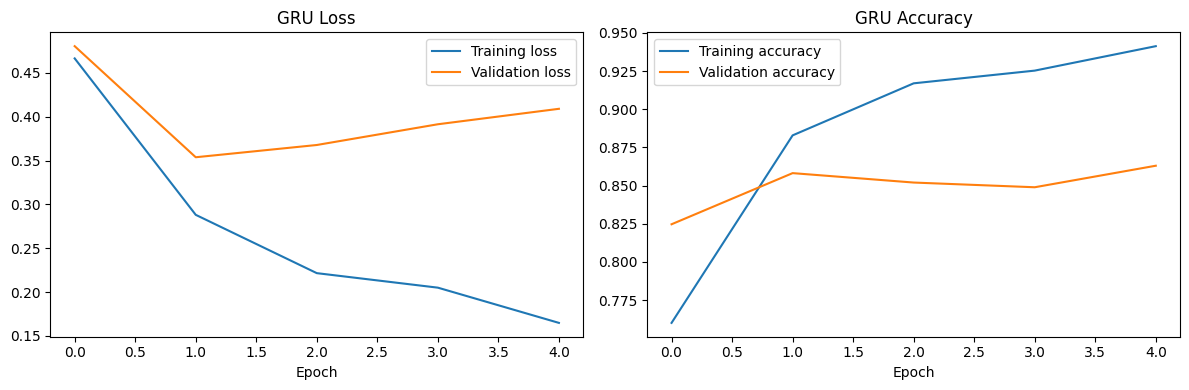

Test accuracy: 0.8551541850220264
              precision    recall  f1-score   support

    negative       0.85      0.86      0.85      2828
    positive       0.86      0.85      0.86      2847

    accuracy                           0.86      5675
   macro avg       0.86      0.86      0.86      5675
weighted avg       0.86      0.86      0.86      5675

ROC-AUC: 0.9327896830778967


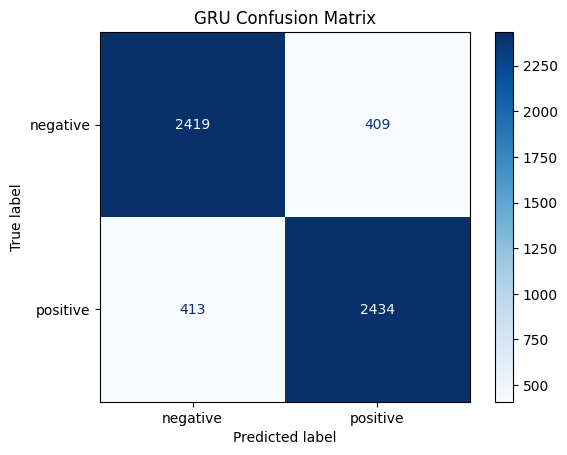

{'accuracy': 0.8551541850220264, 'roc_auc': np.float64(0.9327896830778967), 'classification_report': {'negative': {'precision': 0.8541666666666666, 'recall': 0.8553748231966054, 'f1-score': 0.8547703180212014, 'support': 2828.0}, 'positive': {'precision': 0.8561378825184665, 'recall': 0.854935019318581, 'f1-score': 0.8555360281195079, 'support': 2847.0}, 'accuracy': 0.8551541850220264, 'macro avg': {'precision': 0.8551522745925666, 'recall': 0.8551549212575932, 'f1-score': 0.8551531730703547, 'support': 5675.0}, 'weighted avg': {'precision': 0.85515557442527, 'recall': 0.8551541850220264, 'f1-score': 0.8551544548758057, 'support': 5675.0}}, 'confusion_matrix': [[2419, 409], [413, 2434]], 'training_time_seconds': 42.993242263793945}


In [33]:
import time
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,roc_auc_score, ConfusionMatrixDisplay)

def build_model(model_type='gru', units=64):
    model = keras.Sequential([
        layers.Input(shape=(MAXLEN,)),
        layers.Embedding(input_dim=VOCAB_SIZE, output_dim=32),
        layers.GRU(units),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),loss='binary_crossentropy',metrics=['accuracy'])
    return model

model_gru = build_model('gru', units=64)
model_gru.summary()
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

start_time = time.time()
history_gru = model_gru.fit(X_train, y_train,epochs=15,batch_size=64,validation_split=0.1,callbacks=[early_stop],verbose=1)
gru_training_time = time.time() - start_time
print("GRU training time (seconds):", round(gru_training_time, 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history_gru.history['loss'], label='Training loss')
ax[0].plot(history_gru.history['val_loss'], label='Validation loss')
ax[0].set_title('GRU Loss')
ax[0].set_xlabel('Epoch')
ax[0].legend()

ax[1].plot(history_gru.history['accuracy'], label='Training accuracy')
ax[1].plot(history_gru.history['val_accuracy'], label='Validation accuracy')
ax[1].set_title('GRU Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].legend()
plt.tight_layout()
plt.show()

y_prob_gru = model_gru.predict(X_test, verbose=0).ravel()
y_pred_gru = (y_prob_gru >= 0.5).astype(int)
acc_gru = accuracy_score(y_test, y_pred_gru)
auc_gru = roc_auc_score(y_test, y_prob_gru)

print("Test accuracy:", acc_gru)
print(classification_report(y_test, y_pred_gru, target_names=['negative', 'positive']))
print("ROC-AUC:", auc_gru)

ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred_gru),display_labels=['negative', 'positive']).plot(cmap='Blues')
plt.title('GRU Confusion Matrix')
plt.show()

if 'results' not in globals():
    results = {}

results['GRU'] = {
    'accuracy': acc_gru,
    'roc_auc': auc_gru,
    'classification_report': classification_report(y_test, y_pred_gru, target_names=['negative', 'positive'], output_dict=True),
    'confusion_matrix': confusion_matrix(y_test, y_pred_gru).tolist(),
    'training_time_seconds': gru_training_time
}
print(results['GRU'])

6.5
Gradient flow — all three cells

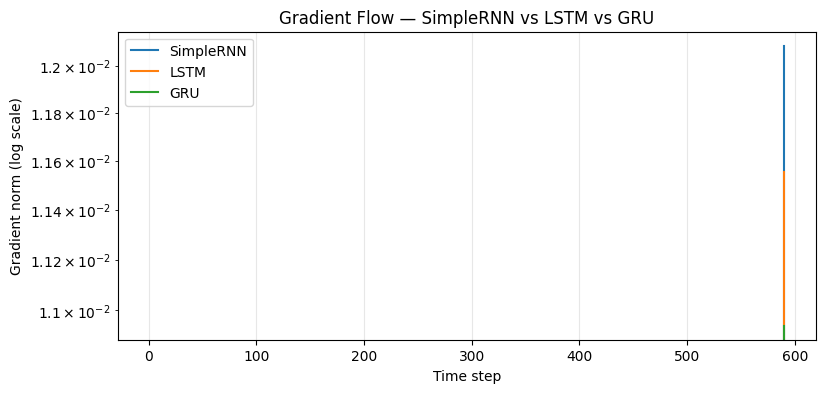

Earliest-step gradient norms:
SimpleRNN: 0.0
LSTM: 0.0
GRU: 0.0


In [34]:
x_batch = tf.convert_to_tensor(X_train[:64], dtype=tf.int32)
y_batch = tf.convert_to_tensor(y_train[:64], dtype=tf.float32)

def get_gradient_norms(cell_type):
    inputs = keras.Input(shape=(MAXLEN,))
    embedded = layers.Embedding(VOCAB_SIZE, 32)(inputs)

    if cell_type == 'lstm':
        hidden_seq = layers.LSTM(64, return_sequences=True)(embedded)
    elif cell_type == 'gru':
        hidden_seq = layers.GRU(64, return_sequences=True)(embedded)
    else:
        hidden_seq = layers.SimpleRNN(64, return_sequences=True)(embedded)

    final_state = layers.Lambda(lambda x: x[:, -1, :])(hidden_seq)
    output = layers.Dense(1, activation='sigmoid')(final_state)
    model = keras.Model(inputs, [output, hidden_seq])

    with tf.GradientTape() as tape:
        pred, hidden = model(x_batch, training=False)
        tape.watch(hidden)
        loss = tf.reduce_mean(
            keras.losses.binary_crossentropy(y_batch, tf.squeeze(pred, axis=-1))
        )

    grad = tape.gradient(loss, hidden)
    return tf.reduce_mean(tf.norm(grad, axis=-1), axis=0).numpy()

rnn_grad = get_gradient_norms('rnn')
lstm_grad = get_gradient_norms('lstm')
gru_grad = get_gradient_norms('gru')

plt.figure(figsize=(9, 4))
plt.plot(range(1, MAXLEN + 1), rnn_grad, label='SimpleRNN')
plt.plot(range(1, MAXLEN + 1), lstm_grad, label='LSTM')
plt.plot(range(1, MAXLEN + 1), gru_grad, label='GRU')
plt.yscale('log')
plt.xlabel('Time step')
plt.ylabel('Gradient norm (log scale)')
plt.title('Gradient Flow — SimpleRNN vs LSTM vs GRU')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Earliest-step gradient norms:")
print("SimpleRNN:", rnn_grad[0])
print("LSTM:", lstm_grad[0])
print("GRU:", gru_grad[0])

6.6
Hidden-unit sensitivity

LSTM 32 accuracy: 0.8469 parameters: 328353
LSTM 64 accuracy: 0.8004 parameters: 344897
LSTM 128 accuracy: 0.7036 parameters: 402561
GRU 32 accuracy: 0.8277 parameters: 326369
GRU 64 accuracy: 0.8425 parameters: 338881
GRU 128 accuracy: 0.8345 parameters: 382337


,Cell,Units,Test Accuracy,Recurrent Parameters,Total Parameters
0,LSTM,32,0.846872,33,328353
1,LSTM,64,0.800352,65,344897
2,LSTM,128,0.703612,129,402561
3,GRU,32,0.827665,33,326369
4,GRU,64,0.842467,65,338881
5,GRU,128,0.834537,129,382337


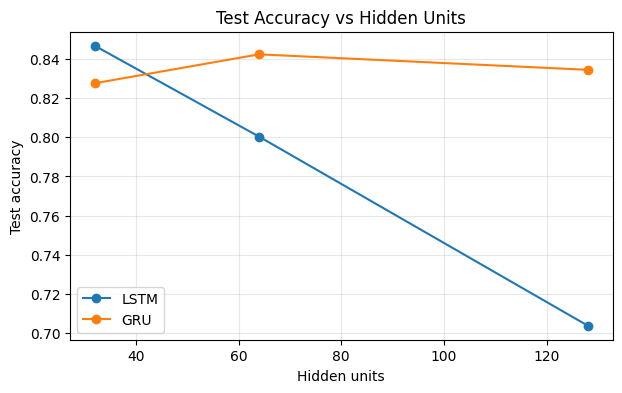

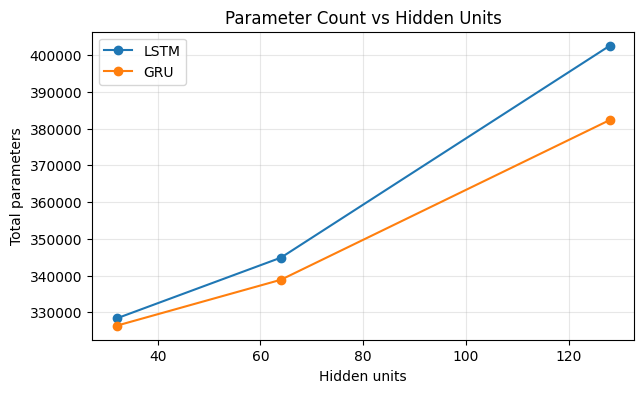

In [35]:
unit_values = [32, 64, 128]
sensitivity_results = []

for cell_type in ['LSTM', 'GRU']:
    for units in unit_values:
        tf.keras.utils.set_random_seed(42)
        recurrent_layer = layers.LSTM(units) if cell_type == 'LSTM' else layers.GRU(units)

        model = keras.Sequential([layers.Input(shape=(MAXLEN,)),layers.Embedding(VOCAB_SIZE, 32),recurrent_layer,layers.Dense(1, activation='sigmoid')])
        model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),loss='binary_crossentropy',metrics=['accuracy'])
        model.fit(X_train, y_train,epochs=6,batch_size=64,validation_split=0.1,verbose=0)
        prob = model.predict(X_test, verbose=0).ravel()
        pred = (prob >= 0.5).astype(int)
        sensitivity_results.append({'Cell': cell_type,'Units': units,'Test Accuracy': accuracy_score(y_test, pred),'Recurrent Parameters': model.layers[2].count_params(),'Total Parameters': model.count_params()})
        print(cell_type, units, "accuracy:", round(accuracy_score(y_test, pred), 4),"parameters:", model.count_params())
sensitivity_df = pd.DataFrame(sensitivity_results)
display(sensitivity_df)

plt.figure(figsize=(7, 4))
for cell_type in ['LSTM', 'GRU']:
    subset = sensitivity_df[sensitivity_df['Cell'] == cell_type]
    plt.plot(subset['Units'], subset['Test Accuracy'], marker='o', label=cell_type)
plt.xlabel('Hidden units')
plt.ylabel('Test accuracy')
plt.title('Test Accuracy vs Hidden Units')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
for cell_type in ['LSTM', 'GRU']:
    subset = sensitivity_df[sensitivity_df['Cell'] == cell_type]
    plt.plot(subset['Units'], subset['Total Parameters'], marker='o', label=cell_type)
plt.xlabel('Hidden units')
plt.ylabel('Total parameters')
plt.title('Parameter Count vs Hidden Units')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

###Task 7: Final Comparison, Inference & Recommendation

7.1
Full results table

In [37]:
import os
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,roc_auc_score, roc_curve, classification_report, confusion_matrix)
np.random.seed(42)
tf.random.set_seed(42)
os.makedirs('plots', exist_ok=True)

In [38]:
model_objects = {
    'ANN baseline': globals().get('ann'),
    'SimpleRNN': globals().get('model_rnn'),
    'LSTM': globals().get('model_lstm'),
    'Stacked LSTM': globals().get('stacked_model'),
    'GRU': globals().get('model_gru')
}

history_objects = {
    'ANN baseline': globals().get('history_ann'),
    'SimpleRNN': globals().get('history_rnn'),
    'LSTM': globals().get('history_lstm'),
    'Stacked LSTM': globals().get('history_stacked'),
    'GRU': globals().get('history_gru')
}

if 'results' not in globals():
    results = {}

comparison_rows = []
metric_rows = []

for name, model in model_objects.items():
    if model is None:
        continue

    history = history_objects.get(name)
    epochs_trained = len(history.history['loss']) if history is not None else np.nan
    time_per_epoch = np.nan
    if history is not None and epochs_trained:
        time_per_epoch = (history.model.optimizer.iterations.numpy() * 0 + np.nan)

    probs = model.predict(X_test, verbose=0).ravel()
    preds = (probs >= 0.5).astype(int)

    accuracy = accuracy_score(y_test, preds)
    precision = precision_score(y_test, preds, zero_division=0)
    recall = recall_score(y_test, preds, zero_division=0)
    f1 = f1_score(y_test, preds, zero_division=0)
    auc = roc_auc_score(y_test, probs)

    old_result = results.get(name, {})
    if name == 'ANN baseline':
        old_result = results.get('ANN', old_result)

    training_time = old_result.get('training_time_seconds', np.nan)
    if name == 'SimpleRNN' and 'training_time_seconds' not in old_result:
        training_time = globals().get('rnn_training_time', np.nan)
    elif name == 'LSTM' and 'training_time_seconds' not in old_result:
        training_time = globals().get('lstm_training_time', np.nan)
    elif name == 'Stacked LSTM' and 'training_time_seconds' not in old_result:
        training_time = globals().get('stacked_training_time', np.nan)
    elif name == 'GRU' and 'training_time_seconds' not in old_result:
        training_time = globals().get('gru_training_time', np.nan)

    time_per_epoch = training_time / epochs_trained if pd.notna(training_time) and epochs_trained else np.nan

    comparison_rows.append({'Model': name,'Parameters': model.count_params(),'Time per Epoch (s)': time_per_epoch,'Epochs Trained': epochs_trained,'Test Accuracy': accuracy})
    metric_rows.append({'Model': name,'Accuracy': accuracy,'Precision': precision,'Recall': recall,'F1': f1,'ROC-AUC': auc})
    results[name] = {**old_result,'accuracy': accuracy,'precision': precision,'recall': recall,'f1': f1,'roc_auc': auc,'parameters': model.count_params(),'epochs_trained': epochs_trained,'time_per_epoch_seconds': time_per_epoch,'predictions': preds,'probabilities': probs}

full_results_df = pd.DataFrame(comparison_rows)
metrics_df = pd.DataFrame(metric_rows)
display(full_results_df)
display(
    metrics_df.style.highlight_max(subset=['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'],color='#ffcccc').format({
        'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}',
        'F1': '{:.4f}', 'ROC-AUC': '{:.4f}'
    })
)

full_results_df.to_csv('plots/full_results.csv', index=False)
metrics_df.to_csv('plots/model_metrics.csv', index=False)
print("Saved results CSV files in plots/")

,Model,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy
0,ANN baseline,1528449,NaN,5,0.860969
1,SimpleRNN,326273,NaN,6,0.834361
2,LSTM,344897,6.338449,5,0.869780
3,Stacked LSTM,357281,14.082693,5,0.851806
4,GRU,338881,8.598648,5,0.855154


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,ANN baseline,0.8610,0.8590,0.8648,0.8619,0.9343
1,SimpleRNN,0.8344,0.8267,0.8476,0.8370,0.9019
2,LSTM,0.8698,0.9133,0.8181,0.8631,0.9408
3,Stacked LSTM,0.8518,0.8580,0.8444,0.8511,0.9255
4,GRU,0.8552,0.8561,0.8549,0.8555,0.9328


Saved results CSV files in plots/


7.2
ROC curves

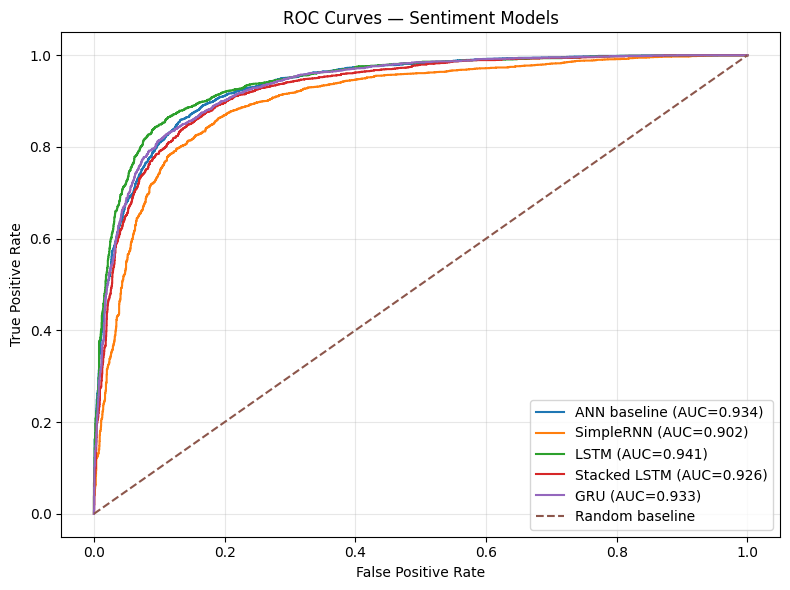

In [39]:
plt.figure(figsize=(8, 6))

for name, model in model_objects.items():
    if model is None:
        continue
    probs = results[name]['probabilities']
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Sentiment Models')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('plots/roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

7.3
Sequence-length robustness



,Model,Review Length,Accuracy,Number of Reviews
0,SimpleRNN,Short (<100),0.842713,693
1,SimpleRNN,Medium (100–250),0.840602,3325
2,SimpleRNN,Long (>250),0.818346,1657
3,LSTM,Short (<100),0.886003,693
4,LSTM,Medium (100–250),0.877293,3325
5,LSTM,Long (>250),0.847918,1657


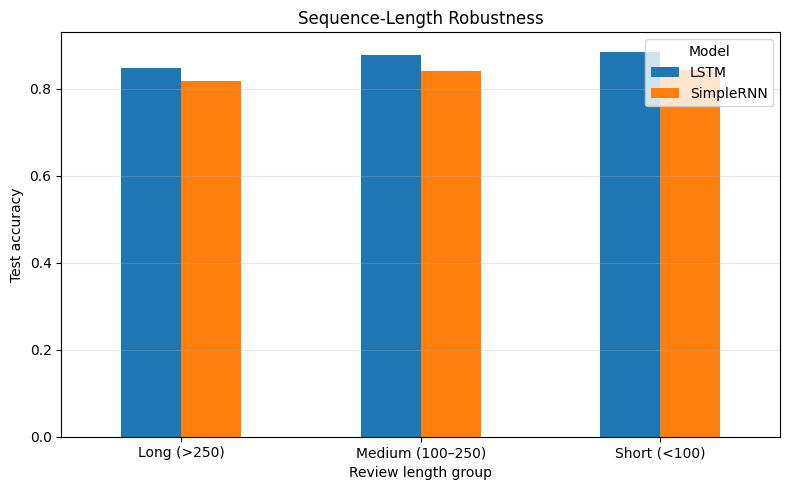

In [40]:
best_gated_name = max(
    ['LSTM', 'GRU'],
    key=lambda name: results[name]['accuracy'] if name in results else -1
)
best_gated_model = model_objects[best_gated_name]
rnn_model_for_length = model_objects.get('SimpleRNN')

test_lengths = np.array([len(str(text).split()) for text in X_test_text])
length_groups = {
    'Short (<100)': test_lengths < 100,
    'Medium (100–250)': (test_lengths >= 100) & (test_lengths <= 250),
    'Long (>250)': test_lengths > 250
}

length_comparison_rows = []
for name, model in [('SimpleRNN', rnn_model_for_length), (best_gated_name, best_gated_model)]:
    if model is None:
        continue
    probs = model.predict(X_test, verbose=0).ravel()
    preds = (probs >= 0.5).astype(int)
    for group_name, mask in length_groups.items():
        if mask.sum() == 0:
            acc = np.nan
        else:
            acc = accuracy_score(y_test[mask], preds[mask])
        length_comparison_rows.append({
            'Model': name,
            'Review Length': group_name,
            'Accuracy': acc,
            'Number of Reviews': int(mask.sum())
        })

length_comparison_df = pd.DataFrame(length_comparison_rows)
display(length_comparison_df)

pivot_length = length_comparison_df.pivot(
    index='Review Length', columns='Model', values='Accuracy'
)
pivot_length.plot(kind='bar', figsize=(8, 5))
plt.xlabel('Review length group')
plt.ylabel('Test accuracy')
plt.title('Sequence-Length Robustness')
plt.xticks(rotation=0)
plt.legend(title='Model')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('plots/sequence_length_robustness.png', dpi=150, bbox_inches='tight')
plt.show()

7.4
Error analysis



In [41]:
best_model_name = max(
    [name for name in model_objects if model_objects[name] is not None],
    key=lambda name: results[name]['f1']
)
best_model = model_objects[best_model_name]
best_probabilities = results[best_model_name]['probabilities']
best_predictions = results[best_model_name]['predictions']

error_df = pd.DataFrame({'review': X_test_text,'cleaned_text': [clean_text(text) for text in X_test_text],'true_label': y_test,'predicted_label': best_predictions,'predicted_probability': best_probabilities})
false_positives = error_df[(error_df['true_label'] == 0) & (error_df['predicted_label'] == 1)].head(4)
false_negatives = error_df[(error_df['true_label'] == 1) & (error_df['predicted_label'] == 0)].head(4)
error_examples = pd.concat([false_positives, false_negatives], axis=0)
error_examples = error_examples[['true_label', 'predicted_label', 'predicted_probability', 'cleaned_text']]
display(error_examples)

error_examples.to_csv('plots/misclassified_reviews.csv', index=False)
print("Best model for error analysis:", best_model_name)
print("False positives shown:", len(false_positives))
print("False negatives shown:", len(false_negatives))

,true_label,predicted_label,predicted_probability,cleaned_text
95,0,1,0.947489,have to admit this version disgraces shakespea...
178,0,1,0.857112,why because for one reason there has never bee...
189,0,1,0.960249,since i'm from norway one of the top ten or so...
208,0,1,0.933314,i saw this movie twice through a pentecostal c...
1,1,0,0.115604,the question of whether or not one likes this ...
14,1,0,0.044618,this video was my first exposure to eddie izza...
31,1,0,0.467557,it was evident until the final credits that th...
32,1,0,0.046053,murder over new york is an entertaining entry ...


Best model for error analysis: LSTM
False positives shown: 4
False negatives shown: 4


7.5
Inference function



In [42]:
def predict_sentiment(text):
    cleaned = clean_text(text)
    sequence = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(sequence, maxlen=MAXLEN, padding='pre', truncating='pre')
    probability = float(best_model.predict(padded, verbose=0).ravel()[0])
    label = 'positive' if probability >= 0.5 else 'negative'
    return label, probability

custom_sentences = [
    "This film is absolutely wonderful and I loved every minute.",
    "This was a terrible and boring movie.",
    "This film is not good.",
    "I cannot say that it was not enjoyable.",
    "Great acting, if your goal was to waste two hours.",
    "Good."
]

custom_results = []
for sentence in custom_sentences:
    label, probability = predict_sentiment(sentence)
    custom_results.append({'Sentence': sentence,'Predicted sentiment': label,'Positive probability': probability})

custom_results_df = pd.DataFrame(custom_results)
display(custom_results_df)

,Sentence,Predicted sentiment,Positive probability
0,This film is absolutely wonderful and I loved ...,positive,0.914662
1,This was a terrible and boring movie.,negative,0.024726
2,This film is not good.,positive,0.530476
3,I cannot say that it was not enjoyable.,positive,0.679398
4,"Great acting, if your goal was to waste two ho...",negative,0.040999
5,Good.,positive,0.583259


In [43]:
requirements = [
    'tensorflow',
    'scikit-learn',
    'pandas',
    'numpy',
    'matplotlib',
    'seaborn'
]

with open('requirements.txt', 'w', encoding='utf-8') as f:
    f.write('\n'.join(requirements) + '\n')

print("Created requirements.txt")
print("Files saved in plots/:")
print(os.listdir('plots'))

Created requirements.txt
Files saved in plots/:
['model_metrics.csv', 'roc_curves.png', 'misclassified_reviews.csv', 'full_results.csv', 'sequence_length_robustness.png']
